# SET50 Phase 3 — 20-session portfolio research

This notebook reviews recorded real-data portfolio simulations. Evaluation dates were previously exposed in Phase 1 and Phase 2; these are not untouched holdout results.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
out=Path(r'C:\Users\Windows 10\Downloads\tradeSim0.2.5\research_set50_portfolio\results\20261027T162905Z_979c875c')
manifest=__import__('json').loads((out/'manifest.json').read_text())
print(manifest['experiment_id'], 'selected E base:',manifest['development_selected_e_base'])

20261027T162905Z_979c875c selected E base: A


## Signal evidence

Momentum20 and SMA20/SMA60 are inconclusive trend hypotheses. Reversal has a stronger one-session rank association, but its top-quintile excess is smaller than round-trip commission. It is used only to reorder near ties.

In [2]:
display(pd.read_csv(out/'factor_evidence.csv'))

,factor,horizon,rank_ic,rank_ic_ci_lo,rank_ic_ci_hi,fdr_q,top_quantile_relative,decision
0,mom_20,5,0.003921,-0.040547,0.04839,9.139879e-01,0.002442,exploratory primary
1,sma20_above_sma60,5,0.022115,-0.015370,0.05960,7.855368e-01,0.002346,exploratory primary
2,reversal_1,1,0.047669,0.034618,0.06072,1.017872e-10,0.001239,tie-breaker only


## Portfolio mechanics

A–D hold six names at 80% target exposure and a 20% stock cap. Equal weight and inverse trailing volatility isolate sizing. C/D add a reversal tie-breaker within 5% of the primary score range. Decisions use only completed prior closes; next opens are modeled with adverse ticks, fees, VAT, 100-share lots and a prior-volume participation cap. E adds rank hysteresis and a 3 percentage-point trade threshold to the development-selected base.

In [3]:
comparison=pd.read_csv(out/'comparison.csv'); display(comparison.round(4))
windows=pd.read_csv(out/'windows.csv'); display(windows.query("role == 'evaluation' and scenario == 'official' and exit_rule == 'scheduled'").groupby('strategy')[['roundtrip_pass','exposure_pass','payoff_pass','drawdown_pass','best_alpha_eligible']].mean())

,strategy,windows,mean_net,median_net,worst_net,mean_excess,median_excess,positive_excess,mean_drawdown,common_pass,best_alpha_pass,mean_turnover,mean_exposure,mean_roundtrips,mean_payoff_thb,median_payoff_thb,mean_commission,mean_vat,mean_slippage
0,A,24,-0.0017,-0.0169,-0.0868,-0.0090,-0.0277,0.3750,0.0515,0.0833,0.0833,2.7940,0.7906,9.0000,-29381.7295,-37183.1562,43935.4222,3075.4796,164589.5833
1,B,24,-0.0049,-0.0153,-0.0837,-0.0122,-0.0251,0.3333,0.0489,0.1250,0.1250,2.9861,0.7893,9.2917,-28550.9811,-31476.1157,46950.9327,3286.5653,172416.8333
2,C,24,-0.0030,-0.0163,-0.0891,-0.0103,-0.0197,0.3750,0.0504,0.1250,0.0833,2.8407,0.7920,9.0833,-29392.5757,-32809.2454,44669.7868,3126.8851,165395.0417
3,D,24,-0.0071,-0.0208,-0.0881,-0.0143,-0.0227,0.3750,0.0494,0.1667,0.1250,3.0873,0.7899,8.9583,-28685.3870,-35302.2294,48539.7735,3397.7841,175832.8750
4,E,24,0.0045,-0.0089,-0.0851,-0.0027,-0.0133,0.4167,0.0467,0.0000,0.0000,1.9257,0.7535,4.6250,-34211.8359,-47123.7622,30301.7217,2121.1205,115492.2917
5,buy_hold,24,-0.0024,-0.0012,-0.0700,-0.0097,-0.0079,0.3333,0.0374,0.0000,0.0000,0.7850,0.7901,0.0000,0.0000,0.0000,12390.5083,867.3356,41852.4167
6,risk_only,24,-0.0016,-0.0156,-0.0813,-0.0089,-0.0256,0.3750,0.0484,0.0833,0.0833,2.6249,0.7422,9.0417,-27884.2341,-34832.3458,41276.3824,2889.3468,154643.5000
7,sma_trend,24,-0.0000,-0.0068,-0.0688,-0.0073,-0.0023,0.4583,0.0449,0.0833,0.0417,1.7730,0.7949,4.7917,-20013.1349,-26361.3163,27906.9497,1953.4865,100777.5417


,roundtrip_pass,exposure_pass,payoff_pass,drawdown_pass,best_alpha_eligible
strategy,,,,,
A,0.958333,1.0,0.125000,0.583333,0.083333
B,0.958333,1.0,0.125000,0.625000,0.125000
C,0.958333,1.0,0.166667,0.541667,0.083333
D,0.958333,1.0,0.166667,0.541667,0.125000
E,0.541667,1.0,0.125000,0.625000,0.000000
buy_hold,0.000000,1.0,0.000000,0.916667,0.000000
risk_only,0.958333,1.0,0.125000,0.625000,0.083333
sma_trend,0.500000,1.0,0.166667,0.666667,0.041667


## Distribution and economic costs

Means hide poor windows. The entire per-window record and cost attribution are available below. The one-tick price adjustment applied to revised historical opens is only a sensitivity estimate, because raw-price adjustment vintages are unavailable.

In [4]:
display(windows.query("role == 'evaluation' and scenario == 'official' and exit_rule == 'scheduled'")[['window','strategy','net_return','excess_return','roundtrips','expected_payoff_thb','best_alpha_eligible']].head(20))
display(pd.read_csv(out/'cost_attribution.csv').groupby('strategy').mean(numeric_only=True).round(0))

,window,strategy,net_return,excess_return,roundtrips,expected_payoff_thb,best_alpha_eligible
44,window_12,buy_hold,-0.002502,-0.047504,0,0.000000,False
45,window_12,A,-0.017868,-0.062871,11,-55664.046130,False
46,window_12,B,-0.022668,-0.067670,10,-63548.063072,False
47,window_12,C,0.010434,-0.034568,10,-33561.216418,False
48,window_12,D,0.008675,-0.036327,9,-38718.632477,False
49,window_12,risk_only,-0.016678,-0.061681,11,-52201.251618,False
50,window_12,E,-0.034819,-0.079822,7,-65422.053436,False
51,window_12,sma_trend,-0.001090,-0.046092,7,-18116.235727,False
52,window_13,buy_hold,-0.069109,-0.053025,0,0.000000,False
53,window_13,A,0.092519,0.108603,4,-30215.324610,False


,commission_thb,vat_thb,slippage_thb,cost_thb
strategy,,,,
A,43935.0,3075.0,164590.0,211600.0
B,46951.0,3287.0,172417.0,222654.0
C,44670.0,3127.0,165395.0,213192.0
D,48540.0,3398.0,175833.0,227770.0
E,30302.0,2121.0,115492.0,147915.0
buy_hold,12391.0,867.0,41852.0,55110.0
risk_only,41276.0,2889.0,154644.0,198809.0
sma_trend,27907.0,1953.0,100778.0,130638.0


## Robustness and uncertainty

Cost, fill and exit scenarios are exploratory. The uncertainty intervals resample the 24 non-overlapping windows as units, so they do not treat stock-days as independent trials. Market regimes below are ex-post diagnostics.

In [5]:
display(pd.read_csv(out/'uncertainty.csv').round(4)); display(pd.read_csv(out/'robustness.csv').round(4)); display(pd.read_csv(out/'regimes_ex_post.csv').round(4))

,strategy,mean_excess,window_bootstrap_lo,window_bootstrap_hi,windows
0,A,-0.0090,-0.0305,0.0140,24
1,B,-0.0122,-0.0316,0.0093,24
2,C,-0.0103,-0.0321,0.0111,24
3,D,-0.0143,-0.0347,0.0067,24
4,E,-0.0027,-0.0237,0.0199,24
5,buy_hold,-0.0097,-0.0246,0.0051,24
6,risk_only,-0.0089,-0.0285,0.0126,24
7,sma_trend,-0.0073,-0.0252,0.0093,24


,strategy,scenario,exit_rule,mean_net,mean_excess,eligibility,turnover,roundtrips
0,A,half_fills,scheduled,-0.0008,-0.0081,0.0000,1.4891,1.2500
1,A,official,rank,0.0041,-0.0032,0.0417,2.1039,6.0417
2,A,official,scheduled,-0.0017,-0.0090,0.0833,2.7940,9.0000
3,A,official,trend_deterioration,-0.0017,-0.0090,0.0833,2.7967,9.0000
4,A,two_ticks,scheduled,-0.0181,-0.0254,0.0000,2.7839,8.9167
5,A,zero,scheduled,0.0195,0.0122,0.1250,2.8087,9.1667
6,B,official,scheduled,-0.0049,-0.0122,0.1250,2.9861,9.2917
7,C,official,scheduled,-0.0030,-0.0103,0.0833,2.8407,9.0833
8,D,official,scheduled,-0.0071,-0.0143,0.1250,3.0873,8.9583
9,E,official,scheduled,0.0045,-0.0027,0.0000,1.9257,4.6250


,strategy,regime_ex_post,windows,mean_excess,eligibility
0,A,down,6,0.0042,0.0000
1,A,sideways,9,0.0048,0.1111
2,A,up,9,-0.0316,0.1111
3,B,down,6,0.0066,0.0000
4,B,sideways,9,0.0002,0.1111
5,B,up,9,-0.0373,0.2222
6,C,down,6,0.0072,0.0000
7,C,sideways,9,0.0048,0.1111
8,C,up,9,-0.0371,0.1111
9,D,down,6,0.0078,0.0000


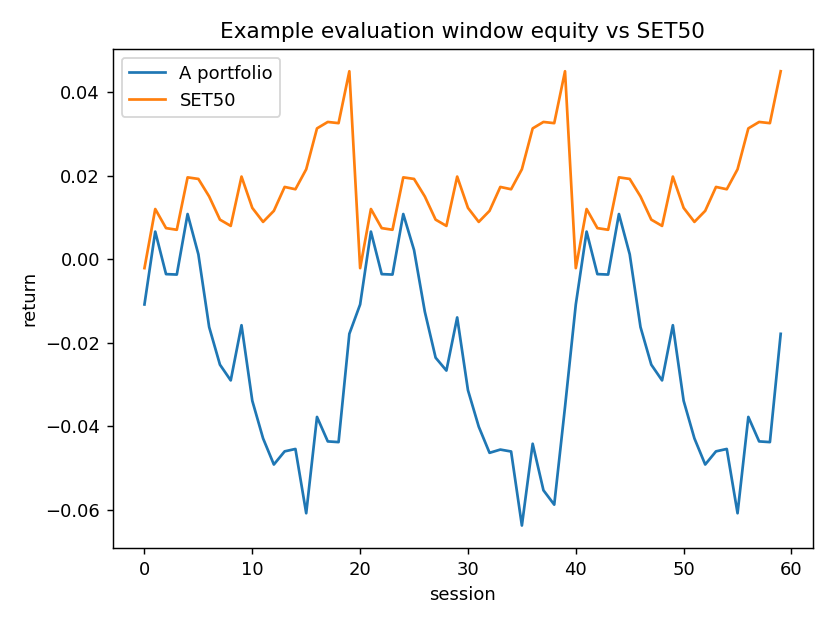

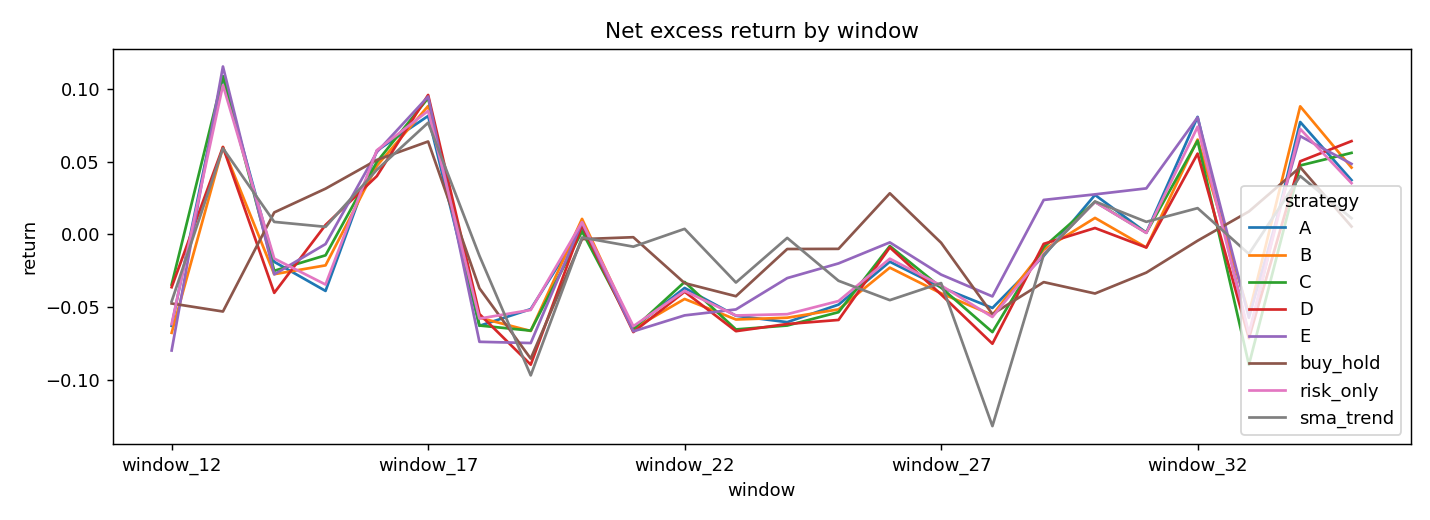

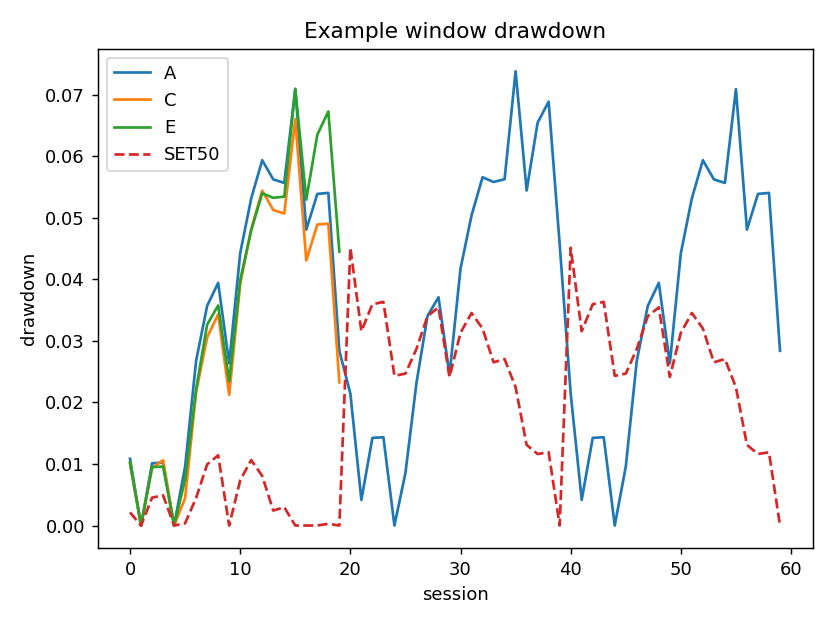

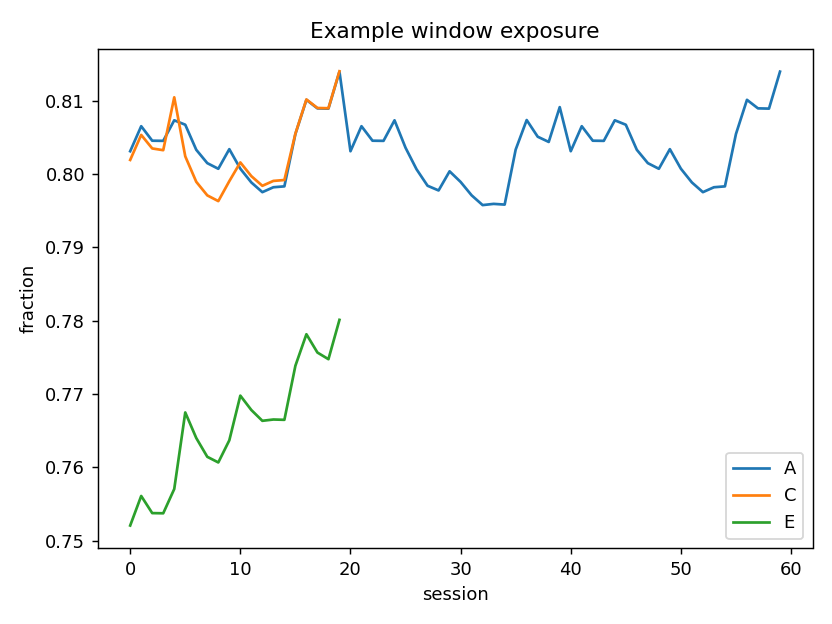

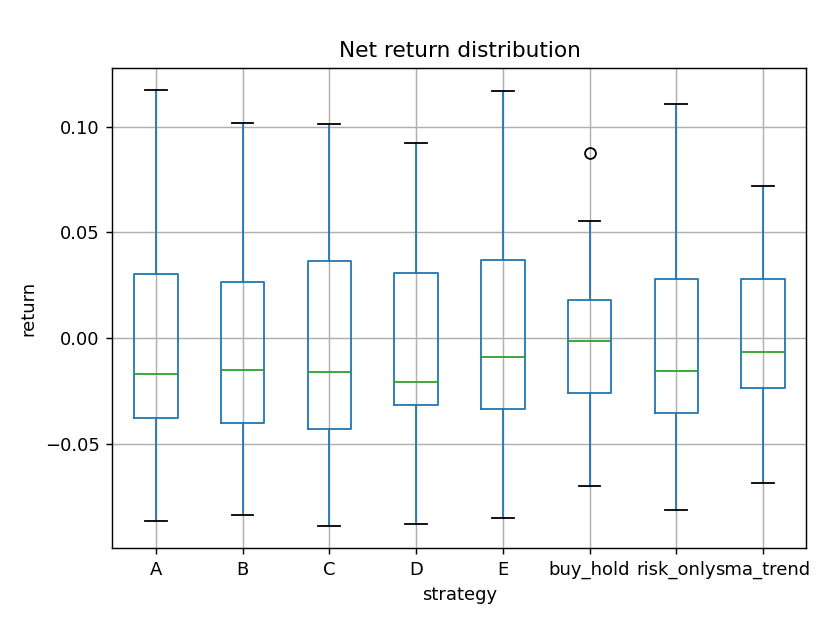

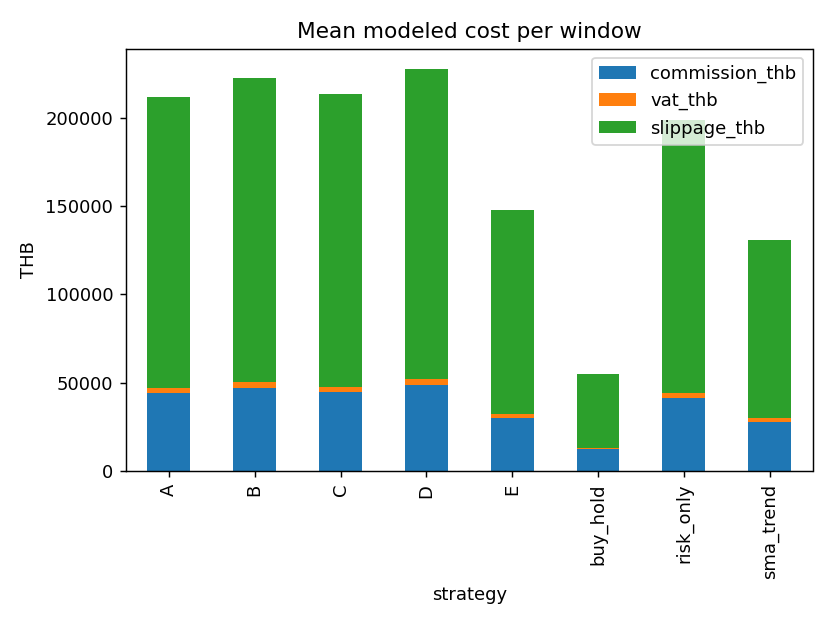

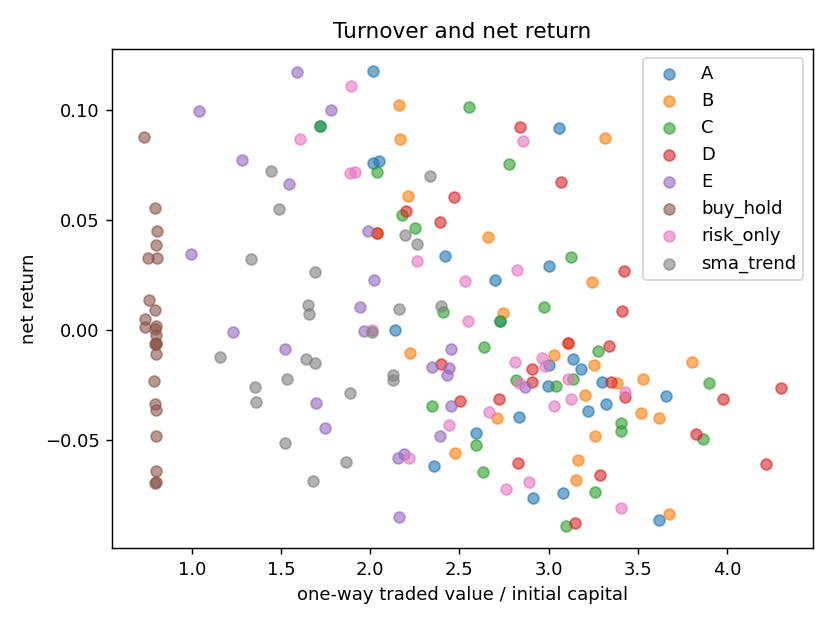

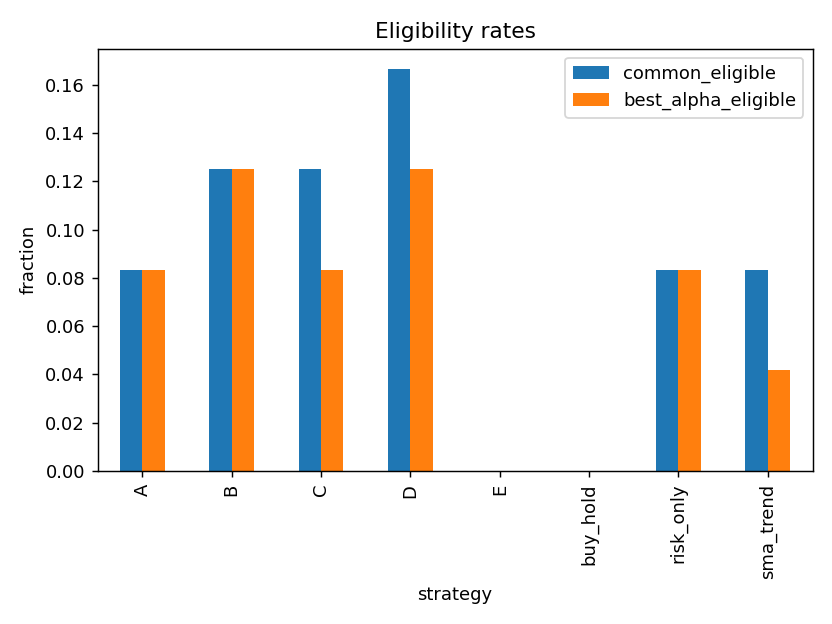

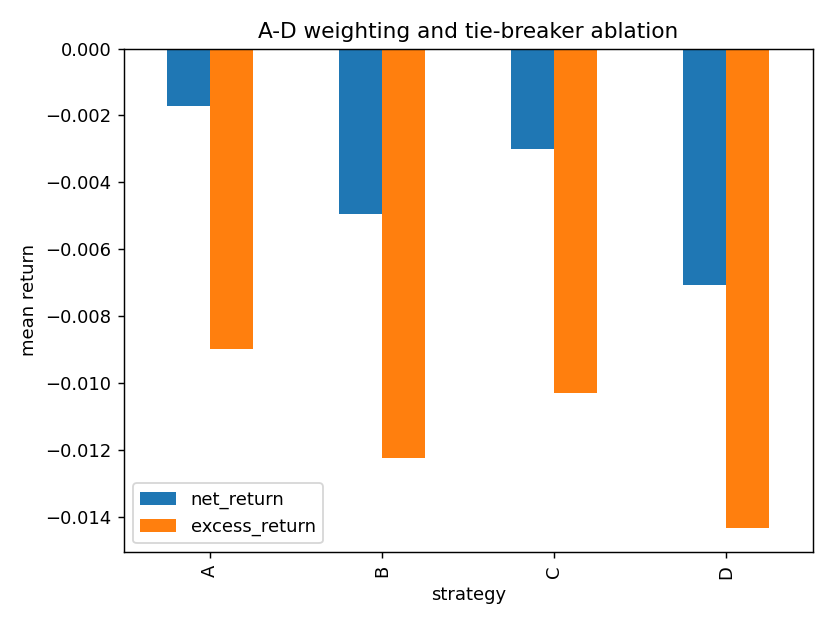

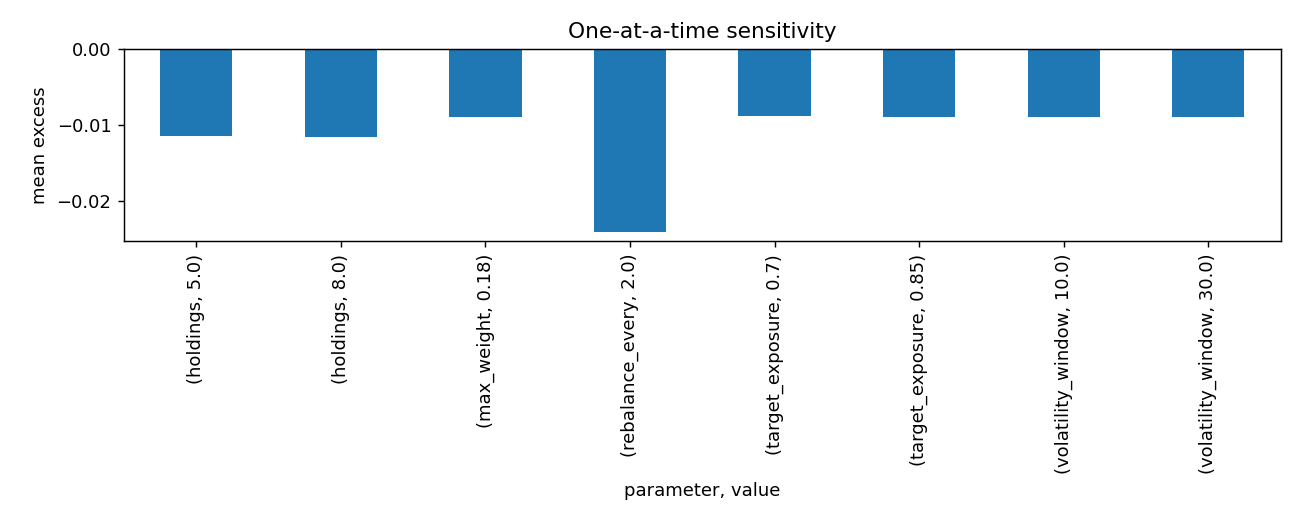

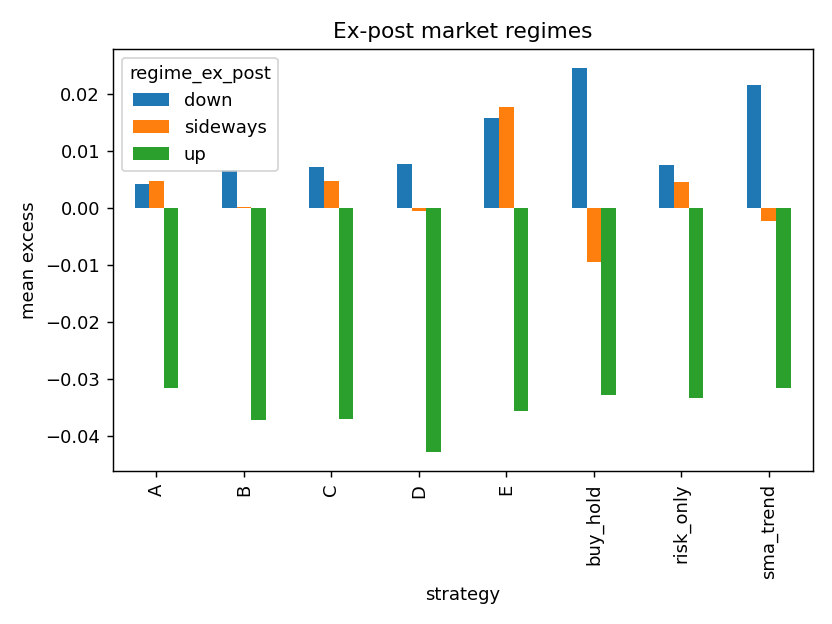

In [6]:
for name in ['equity','window_excess','drawdown','exposure','return_distribution','costs','turnover_performance','eligibility','weighting','sensitivity','regimes']:
    display(Image(filename=str(out/'figures'/(name+'.png'))))

## Conclusion

Compare A/C and B/D to assess the incremental reversal signal. Check E's natural FIFO completions alongside turnover. These previously exposed periods and adjusted-price execution approximations cannot prove a competition edge. The Phase 4 gate is to validate executable prices and gather fresh chronological data before considering ML.